In [ ]:
import pandas as pd
import nltk
import matplotlib.pyplot as plt
df=pd.read_csv('/content/whatsapp_reviews.csv',encoding="ISO-8859-1")
df

,review_id,rating,review_text,review_date,helpful
0,56887e3c-1684-4ced-834e-befc7a66fc7d,5,Great ð,11/26/2025 22:08,0
1,0da4488e-7158-4ea6-bcb9-17b9b3867642,1,plz whats up unban,11/26/2025 22:08,0
2,5a20e8e3-9e00-4360-a539-16953e309a3a,1,my contact didn't show on WhatsApp .. for priv...,11/26/2025 22:06,0
3,0cf26263-1c10-473e-ae15-d6390884fef7,1,Can you guys let archived group chats stay arc...,11/26/2025 22:05,1
4,54eebd96-041e-4baf-a8f1-adf603658c28,5,it is the g.o.a.tð¿ð¼,11/26/2025 22:04,0
...,...,...,...,...,...
5395,8caf4de7-d4f7-4807-aeb8-feb23813348c,5,it's really excellent app,11/21/2025 19:57,0
5396,5b50a06d-cdd1-49eb-9ad2-e67ce747de96,5,it's very secret options all is clear but they...,11/21/2025 19:56,0
5397,d0d951c4-8948-4f35-826a-6f3d7e4e52fd,5,best app in the world ðð,11/21/2025 19:55,0
5398,cfe66013-059d-4750-820d-f3d9bda783fb,5,the best,11/21/2025 19:55,0


In [ ]:
#DATA UNDERSTANDING

#first 3 rows
print(df.head(3))

                              review_id  rating  \
0  56887e3c-1684-4ced-834e-befc7a66fc7d       5   
1  0da4488e-7158-4ea6-bcb9-17b9b3867642       1   
2  5a20e8e3-9e00-4360-a539-16953e309a3a       1   

                                         review_text       review_date  \
0                                         Great ð  11/26/2025 22:08   
1                                 plz whats up unban  11/26/2025 22:08   
2  my contact didn't show on WhatsApp .. for priv...  11/26/2025 22:06   

   helpful  
0        0  
1        0  
2        0  


In [ ]:
#last 3 rows
print(df.tail(3))

                                 review_id  rating  \
5397  d0d951c4-8948-4f35-826a-6f3d7e4e52fd       5   
5398  cfe66013-059d-4750-820d-f3d9bda783fb       5   
5399  2371d0ea-d934-44bf-98ee-75febe995c4a       5   

                         review_text       review_date  helpful  
5397  best app in the world ðð  11/21/2025 19:55        0  
5398                        the best  11/21/2025 19:55        0  
5399               open the whatsapp  11/21/2025 19:54        0  


In [ ]:
#number of rows and columns
print(df.shape)
#dimension
print(df.ndim)

(5400, 5)
2


In [ ]:
#statistical summary
print(df.describe(include=object))

                                   review_id review_text       review_date
count                                   5400        5400              5400
unique                                  5400        5023              3674
top     2371d0ea-d934-44bf-98ee-75febe995c4a    good app  11/26/2025 18:25
freq                                       1          71                 6


In [ ]:
#complete informations
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5400 entries, 0 to 5399
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    5400 non-null   object
 1   rating       5400 non-null   int64 
 2   review_text  5400 non-null   object
 3   review_date  5400 non-null   object
 4   helpful      5400 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 211.1+ KB
None


In [ ]:
#unique values in target columns
print(df['helpful'].unique())

[     0      1      2     48      5      3      4     17     10     34
      6     18     44     11      9     95     12     22     20     70
     23     82     38   1884     36     14    188      8    305      7
     67    121   8696     16     15     47     80     76    113     30
    191     19     13    101 248962     29   1688     56     45     42
     33   4345     26     28]


In [ ]:
#column names
print(df.columns)
#numerical column names
print(df.select_dtypes(exclude=object).columns)
#non numerical column names
print(df.select_dtypes(include=object).columns)

Index(['review_id', 'rating', 'review_text', 'review_date', 'helpful'], dtype='object')
Index(['rating', 'helpful'], dtype='object')
Index(['review_id', 'review_text', 'review_date'], dtype='object')


In [ ]:
#duplicate values
print(df.duplicated().sum())

0


In [ ]:
#null values
print(df.isnull().sum())

review_id      0
rating         0
review_text    0
review_date    0
helpful        0
dtype: int64


In [ ]:
#datatype of column
print(df.dtypes)

review_id      object
rating          int64
review_text    object
review_date    object
helpful         int64
dtype: object


In [ ]:
#DATA CLEANING

#removing columns which is less important for review
df=df.drop(['review_id','review_date','helpful'],axis=1)
df

,rating,review_text
0,5,Great ð
1,1,plz whats up unban
2,1,my contact didn't show on WhatsApp .. for priv...
3,1,Can you guys let archived group chats stay arc...
4,5,it is the g.o.a.tð¿ð¼
...,...,...
5395,5,it's really excellent app
5396,5,it's very secret options all is clear but they...
5397,5,best app in the world ðð
5398,5,the best


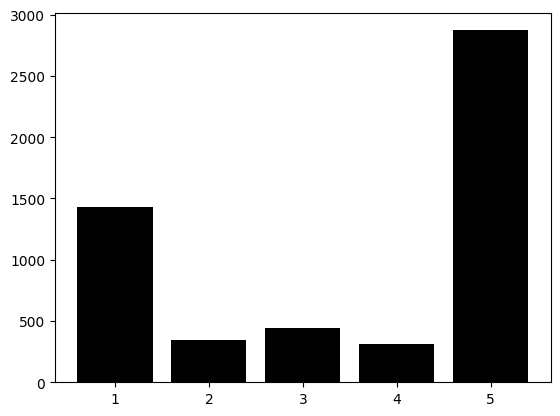

In [ ]:
#target column barchart
xlab=df['rating'].unique()
ylab=df['rating'].value_counts()
plt.bar(xlab,ylab,color='black')
plt.show()

In [ ]:
#NLP PREPROCESSING STEPS

#defining review_text column to a variable
review=df['review_text']
review

,review_text
0,Great ð
1,plz whats up unban
2,my contact didn't show on WhatsApp .. for priv...
3,Can you guys let archived group chats stay arc...
4,it is the g.o.a.tð¿ð¼
...,...
5395,it's really excellent app
5396,it's very secret options all is clear but they...
5397,best app in the world ðð
5398,the best


In [ ]:
#TOKENIZATION
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
review = review.apply(lambda x: " ".join(word_tokenize(x)))
review

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,review_text
0,Great ð
1,plz whats up unban
2,my contact did n't show on WhatsApp .. for pri...
3,Can you guys let archived group chats stay arc...
4,it is the g.o.a.tð¿ð¼
...,...
5395,it 's really excellent app
5396,it 's very secret options all is clear but the...
5397,best app in the world ðð
5398,the best


In [ ]:
#REMOVING SPECIAL CHARACTERS
review=review.replace('[^a-zA-Z0-9]',' ',regex=True)
review

,review_text
0,Great
1,plz whats up unban
2,my contact did n t show on WhatsApp for pri...
3,Can you guys let archived group chats stay arc...
4,it is the g o a t
...,...
5395,it s really excellent app
5396,it s very secret options all is clear but the...
5397,best app in the world
5398,the best


In [ ]:
#removing words less than 3 letters
review=review.apply(lambda x:" ".join([i for i in word_tokenize(x) if len(i) >= 3]))
review

,review_text
0,Great
1,plz whats unban
2,contact did show WhatsApp for privacy share sc...
3,Can you guys let archived group chats stay arc...
4,the
...,...
5395,really excellent app
5396,very secret options all clear but they have meet
5397,best app the world
5398,the best


In [ ]:
#stemming to get rootwords and removing stopwords
nltk.download('stopwords')
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords
st=stopwords.words('english')
ss=SnowballStemmer('english')
review = review.apply(lambda x: " ".join([ss.stem(i.lower()) for i in word_tokenize(x) if i.lower() not in st]))
review


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,review_text
0,great
1,plz what unban
2,contact show whatsapp privaci share screenshot...
3,guy let archiv group chat stay archiv archiv r...
4,
...,...
5395,realli excel app
5396,secret option clear meet
5397,best app world
5398,best


In [ ]:
#VECTORIZATION-TF IDF
from sklearn.feature_extraction.text import TfidfVectorizer
vector=TfidfVectorizer()
data=vector.fit_transform(review)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 34907 stored elements and shape (5400, 3362)>

In [ ]:
#INPUT OUTPUT SEPARATION
x=data
y=df['rating']
x

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 34907 stored elements and shape (5400, 3362)>

In [ ]:
#TRAIN-TEST-SPLITTING
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.30,random_state=41)
print(xtrain.shape)
print(ytrain.shape)
print(xtest.shape)
print(ytest.shape)

(3780, 3362)
(3780,)
(1620, 3362)
(1620,)


In [ ]:
#DATA BALANCING
print(ytrain.value_counts())
from imblearn.over_sampling import SMOTE
sm=SMOTE()
xtrain1,ytrain1=sm.fit_resample(xtrain,ytrain)
print(ytrain1.value_counts())


rating
5    2004
1     996
4     320
3     234
2     226
Name: count, dtype: int64
rating
1    2004
5    2004
4    2004
2    2004
3    2004
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import GridSearchCV
#HYPERPARAMETER TUNING FOR KNN
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier()
knn_param={'n_neighbors':[5,7,9,11],'weights':['uniform','distance'],'metric':['euclidean','manhattan']}
knn_grid=GridSearchCV(knn_model,knn_param,cv=3,scoring="accuracy")
#training
knn_grid.fit(xtrain1,ytrain1)
#best performing parameters
knn_grid.best_params_

{'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'distance'}

In [ ]:
#KNN MODEL BUILDING
knn=KNeighborsClassifier(metric= 'euclidean', n_neighbors=5, weights='distance')
knn.fit(xtrain1,ytrain1)
knn_ypred=knn.predict(xtest)
knn_ypred

array([3, 5, 4, ..., 1, 4, 4])

In [ ]:
#HYPERPARAMETER TUNING OF NB
from sklearn.naive_bayes import BernoulliNB
nb_model=BernoulliNB()
nb_param={'alpha':[0.1,0.5,1.0,5.0,10.0],'binarize':[0.0,0.5,1.0],'fit_prior':[True,False]}
nb_grid=GridSearchCV(nb_model,nb_param,cv=3,scoring='accuracy')
nb_grid.fit(xtrain1,ytrain1)
#best performing parameters
nb_grid.best_params_

{'alpha': 0.1, 'binarize': 0.0, 'fit_prior': True}

In [ ]:
#NB MODEL BUILDING
nb=BernoulliNB(alpha= 0.1, binarize= 0.0, fit_prior= True)
nb.fit(xtrain1,ytrain1)
nb_ypred=nb.predict(xtest)
nb_ypred

array([5, 5, 1, ..., 4, 5, 1])

In [ ]:
#HYPERPARAMETER TUNING FOR DECISION TREE
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier(random_state=41)
dt_param={'criterion':['gini','entropy','log_loss'],'max_depth':[3,5,7,10,None],
          'min_samples_split':[2,4,5],'min_samples_leaf':[1,2,4]}
dt_grid=GridSearchCV(dt_model,dt_param,cv=3,scoring='accuracy')
dt_grid.fit(xtrain1,ytrain1)
dt_grid.best_params_

{'criterion': 'gini',
 'max_depth': None,
 'min_samples_leaf': 1,
 'min_samples_split': 2}

In [ ]:
#DT MODEL BUILDING
dt=DecisionTreeClassifier(criterion= 'gini',max_depth= None,min_samples_leaf= 1,min_samples_split= 2,random_state=41)
dt.fit(xtrain1,ytrain1)
dt_ypred=dt.predict(xtest)
dt_ypred

array([5, 5, 1, ..., 1, 2, 1])

In [ ]:
#HYPERPARAMETER TUNING FOR RANDOM FOREST
from sklearn.ensemble import RandomForestClassifier
rfc_model=RandomForestClassifier(random_state=41)
rfc_param={'n_estimators':[100,200],'max_depth':[5,10,15,None],'min_samples_split':[2,4,5],'min_samples_leaf':[1,2,4]}
rfc_grid=GridSearchCV(rfc_model,rfc_param,cv=3,scoring='accuracy')
rfc_grid.fit(xtrain1,ytrain1)
rfc_grid.best_params_

{'max_depth': None,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 200}

In [ ]:
#RANDOMFOREST MODEL BUILDING
rfc=RandomForestClassifier(max_depth= None,min_samples_leaf= 1,min_samples_split= 2,n_estimators= 200,random_state=41)
rfc.fit(xtrain1,ytrain1)
rfc_ypred=rfc.predict(xtest)
rfc_ypred

array([5, 5, 1, ..., 1, 5, 1])

In [ ]:
#HYPERPARAMETER TUNING FOR LOGISTIC REGRESSION
from sklearn.linear_model import LogisticRegression
lr_model=LogisticRegression(random_state=41)
lr_param={'C':[0.01,0.1,1,10],'penalty':['l1','l2'],'solver':['liblinear']}
lr_grid=GridSearchCV(lr_model,lr_param,cv=3,scoring='accuracy')
lr_grid.fit(xtrain1,ytrain1)
lr_grid.best_params_

{'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}

In [ ]:
#LOGISTIC REGRESSION MODEL BUILDING
lr=LogisticRegression(C= 10, penalty= 'l1',solver= 'liblinear',random_state=41)
lr.fit(xtrain1,ytrain1)
lr_ypred=lr.predict(xtest)
lr_ypred

array([5, 1, 1, ..., 5, 5, 1])

In [ ]:
#TRAINING ANd TESTING SCORE
print("KNN  Training Score:",knn.score(xtrain1,ytrain1),  "Testing score:",knn.score(xtest,ytest))
print("NB Training Score:",nb.score(xtrain1,ytrain1), "Testing score:",nb.score(xtest,ytest))
print("DT Training Score:",dt.score(xtrain1,ytrain1), "Testing score:",dt.score(xtest,ytest))
print("RFC  Training Score:",rfc.score(xtrain1,ytrain1),  "Testing score:",rfc.score(xtest,ytest))
print("LR Training Score:",lr.score(xtrain1,ytrain1), "Testing score:",lr.score(xtest,ytest))

KNN  Training Score: 0.9577844311377246 Testing score: 0.32592592592592595
NB Training Score: 0.7033932135728543 Testing score: 0.6074074074074074
DT Training Score: 0.9603792415169661 Testing score: 0.5333333333333333
RFC  Training Score: 0.9595808383233533 Testing score: 0.6259259259259259
LR Training Score: 0.865568862275449 Testing score: 0.4567901234567901


In [ ]:
#PERFORMANCE EVALUATION
#ACCURACY
from sklearn.metrics import accuracy_score
print("KNN accuracy:",accuracy_score(ytest,knn_ypred))
print("NB accuracy:",accuracy_score(ytest,nb_ypred))
print("DT accuracy:",accuracy_score(ytest,dt_ypred))
print("RFC accuracy:",accuracy_score(ytest,rfc_ypred))
print("LR accuracy:",accuracy_score(ytest,lr_ypred))

KNN accuracy: 0.32592592592592595
NB accuracy: 0.6074074074074074
DT accuracy: 0.5333333333333333
RFC accuracy: 0.6259259259259259
LR accuracy: 0.4567901234567901
